# Nine parameters learning XOR

Read reports/LEARNING_GUIDE.md for the derivation and failure explanations. Run cells in order from this folder. No deep-learning framework or external dataset is needed.

In [1]:
from pathlib import Path
import json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from model import X, Y, initialize, loss_and_gradient, predict_proba
from check_gradients import check_gradient
from train import train
ROOT = Path.cwd()
assert (ROOT / "model.py").is_file()

## Verify the hand-written gradient before training

In [2]:
check = check_gradient(initialize(0))
print(check["relative_l2_error"])
assert check["relative_l2_error"] < 1e-5
for component in check["components"]: print(component)

4.7110898905182226e-11
{'parameter': 'W1_00', 'analytic': 0.01163893235292715, 'numeric': 0.01163893234568114, 'absolute_error': 7.246011082817638e-12}
{'parameter': 'W1_01', 'analytic': 3.771710126274086e-05, 'numeric': 3.7717096112999116e-05, 'absolute_error': 5.149741744148173e-12}
{'parameter': 'W1_10', 'analytic': 0.08234244325360775, 'numeric': 0.08234244325278084, 'absolute_error': 8.269079865286244e-13}
{'parameter': 'W1_11', 'analytic': 0.07310825705591809, 'numeric': 0.07310825705375557, 'absolute_error': 2.1625201629404955e-12}
{'parameter': 'b1_0', 'analytic': -0.027461152528674815, 'numeric': -0.027461152524166362, 'absolute_error': 4.508452638996019e-12}
{'parameter': 'b1_1', 'analytic': 0.0015827464202143593, 'numeric': 0.0015827464172613046, 'absolute_error': 2.9530546844652728e-12}
{'parameter': 'w2_0', 'analytic': 0.04710833679586125, 'numeric': 0.047108336798107324, 'absolute_error': 2.2460713844374425e-12}
{'parameter': 'w2_1', 'analytic': 0.007873768372172862, 'num

## Train the predeclared primary example
Success means mean BCE <= 0.02 and all four truth-table entries correct. This is not held-out accuracy or a claim of a finite global minimizer.

In [3]:
result = train("adam", seed=0)
print(result.success, result.reason, result.iterations, result.loss, result.accuracy)
print(np.column_stack([X, Y, predict_proba(result.theta)]))
assert result.success
assert check_gradient(result.theta)["relative_l2_error"] < 1e-5

True target_loss_and_accuracy 194 0.019916742555868474 1.0
[[-1.         -1.          0.          0.0237939 ]
 [-1.          1.          1.          0.98209213]
 [ 1.         -1.          1.          0.98237144]
 [ 1.          1.          0.          0.01953611]]


## Demonstrate the exact zero-initialization trap

In [4]:
zero = train("adam", initial=np.zeros(9))
print(zero.reason, zero.loss, zero.accuracy)
assert zero.iterations == 0 and not zero.success

stationary_before_target 0.6931471805599453 0.5


## Reproduce all 20 paired starts and the labeled stress cases
This regenerates the CSV tables and plots; failure runs are retained.

XOR seed 0: complete


XOR seed 1: complete


XOR seed 2: complete


XOR seed 3: complete


XOR seed 4: complete


...

XOR seed 16: complete


XOR seed 17: complete


XOR seed 18: complete


XOR seed 19: complete


{
  "primary_loss": 0.019916742555868474,
  "primary_accuracy": 1.0,
  "optimizer_summary": [
    {
      "method": "gd",
      "seeds": 20,
      "successes": 12,
      "failures": 8,
      "mean_final_loss": 0.15063694845472994,
      "median_iterations_successes": 190.0,
      "mean_accuracy": 0.8
    },
    {
      "method": "momentum",
      "seeds": 20,
      "successes": 12,
      "failures": 8,
      "mean_final_loss": 0.150515790374039,
      "median_iterations_successes": 88.0,
      "mean_accuracy": 0.8
    },
    {
      "method": "adam",
      "seeds": 20,
      "successes": 10,
      "failures": 10,
      "mean_final_loss": 0.1832482511441093,
      "median_iterations_successes": 229.0,
      "mean_accuracy": 0.825
    }
  ]
}
{'method': 'gd', 'seeds': 20, 'successes': 12, 'failures': 8, 'mean_final_loss': 0.15063694845472994, 'median_iterations_successes': 190.0, 'mean_accuracy': 0.8}
{'method': 'momentum', 'seeds': 20, 'successes': 12, 'failures': 8, 'mean_final_loss': 

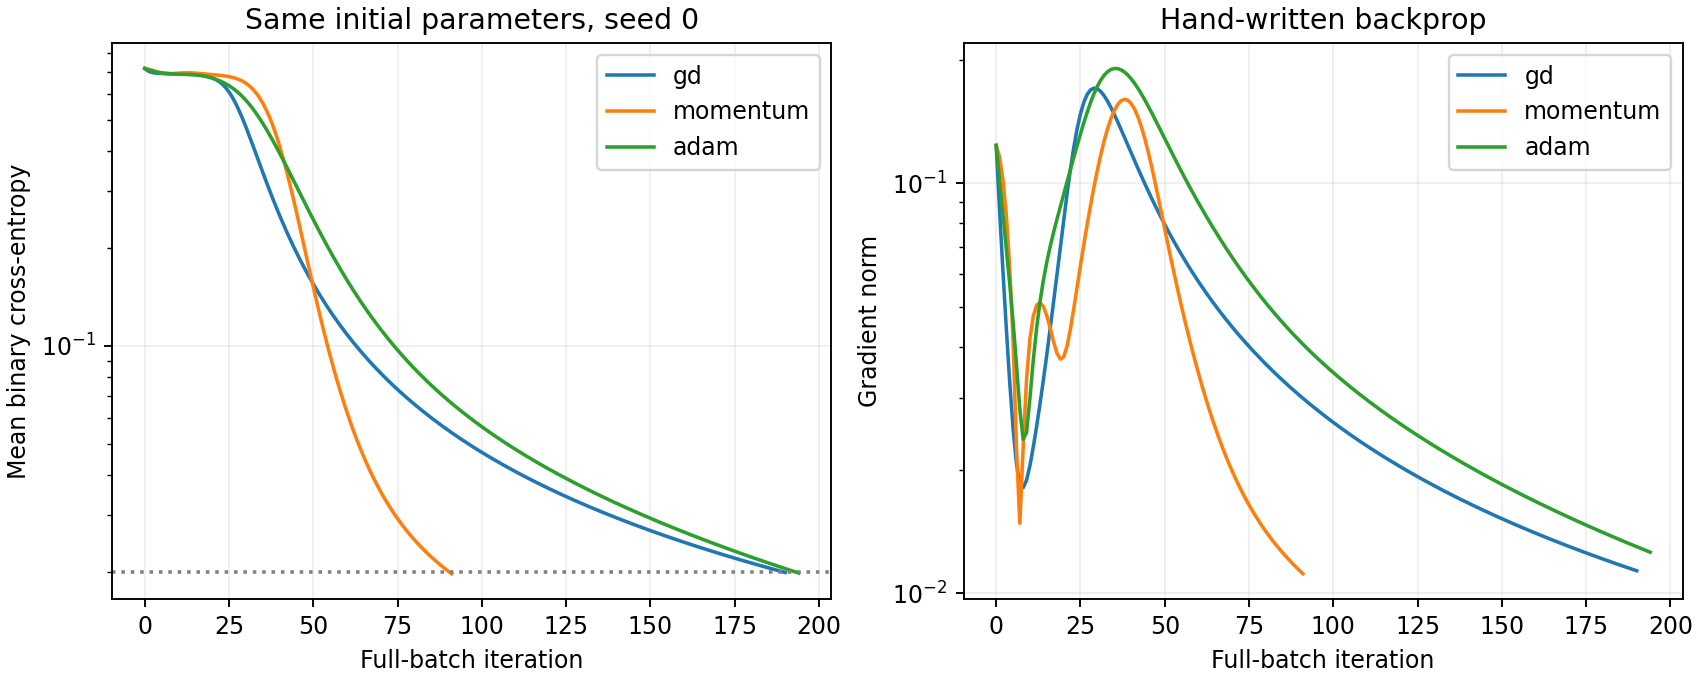

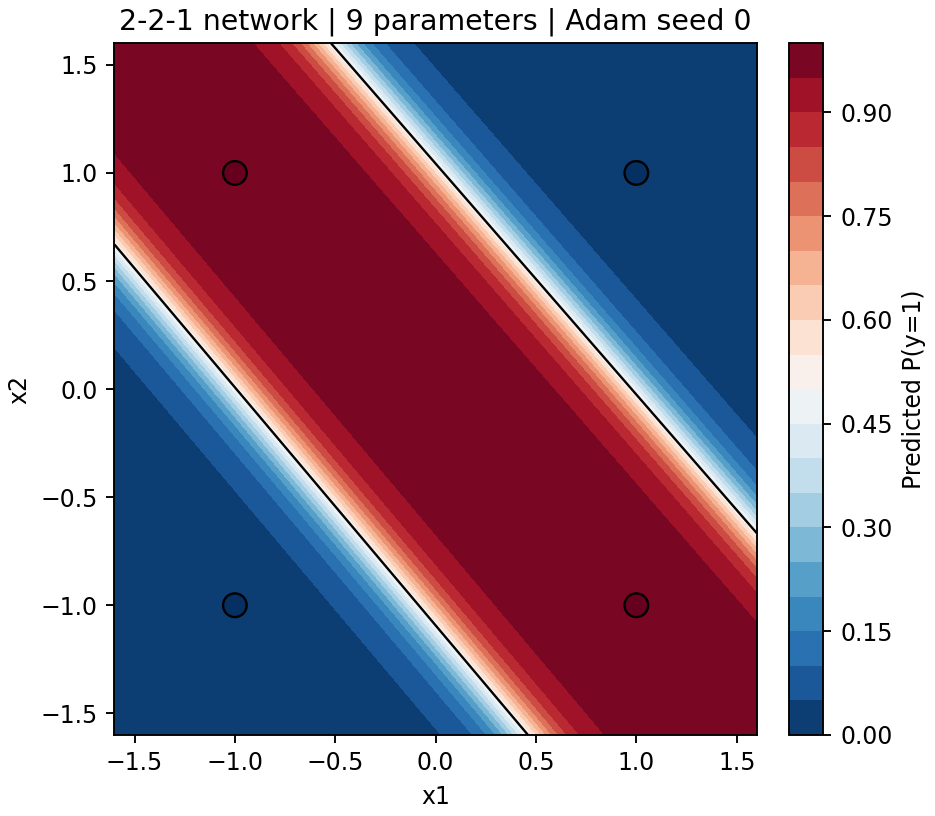

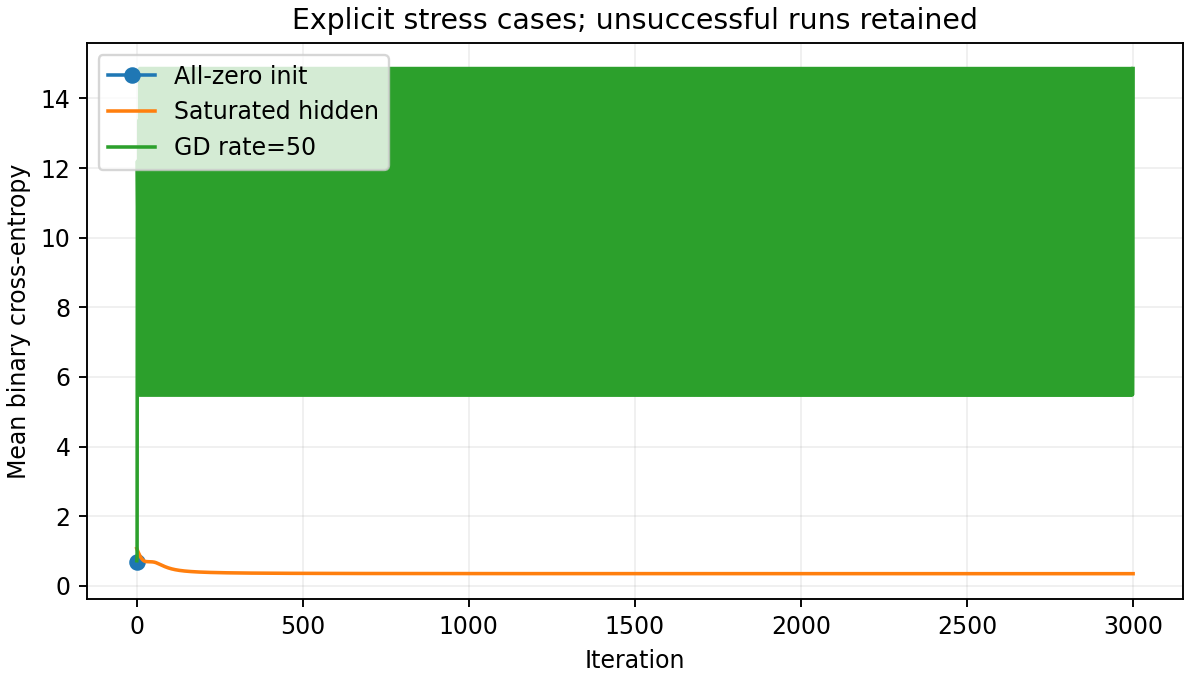

In [5]:
from run_experiment import run
summary = run()
for row in summary["optimizer_summary"]: print(row)
display(Image(filename="results/training_curves.png"))
display(Image(filename="results/decision_boundary.png"))
display(Image(filename="results/stress_curves.png"))

## Test structural properties and optimizer behavior

In [6]:
import subprocess, sys
checks = subprocess.run([sys.executable, "-m", "pytest", "-q", "test_model.py"], capture_output=True, text=True)
print(checks.stdout)
assert checks.returncode == 0, checks.stderr

...............                                                          [100%]
15 passed in 0.37s

